##  Cull Lion Data

In [18]:
pip install geopandas pyogrio pyarrow

Note: you may need to restart the kernel to use updated packages.


In [19]:
import geopandas as gpd
import pandas as pd
import pyogrio

gdb = "/Users/temp/Documents/GitHub/MappingAffordances/Data_Input/Streets and Base/lion.gdb"

wanted = [
    "Street",
    "FeatureTyp",
    "RB_Layer",
    "NonPed",
    "SegmentID",
    "PhysicalID",
    "LBoro",
    "RW_TYPE",
    "Status",
    "Carto_Display_Level",
    "StreetWidth_Min",
    "StreetWidth_Max",
    "Number_Travel_Lanes",
    "POSTED_SPEED",
]

# Match wanted names to the file's actual names, ignoring case
actual = list(pyogrio.read_info(gdb, layer="lion")["fields"])
lookup = {name.lower(): name for name in actual}
found = {w: lookup[w.lower()] for w in wanted if w.lower() in lookup}
missing = [w for w in wanted if w.lower() not in lookup]
print("Missing:", missing)

lion = gpd.read_file(gdb, layer="lion", columns=list(found.values()))
lion = lion.rename(columns={v: k for k, v in found.items()})

Missing: []


In [20]:
import pyogrio

fields = pyogrio.read_info(gdb, layer="lion")["fields"]
print(list(fields))

['Street', 'SAFStreetName', 'FeatureTyp', 'SegmentTyp', 'IncExFlag', 'RB_Layer', 'NonPed', 'TrafDir', 'TrafSrc', 'SpecAddr', 'FaceCode', 'SeqNum', 'StreetCode', 'SAFStreetCode', 'LGC1', 'LGC2', 'LGC3', 'LGC4', 'LGC5', 'LGC6', 'LGC7', 'LGC8', 'LGC9', 'BOE_LGC', 'SegmentID', 'SegCount', 'LocStatus', 'LZip', 'RZip', 'LBoro', 'RBoro', 'L_CD', 'R_CD', 'LATOMICPOLYGON', 'RATOMICPOLYGON', 'LCT2020', 'LCT2020Suf', 'RCT2020', 'RCT2020Suf', 'LCB2020', 'LCB2020Suf', 'RCB2020', 'RCB2020Suf', 'LCT2010', 'LCT2010Suf', 'RCT2010', 'RCT2010Suf', 'LCB2010', 'LCB2010Suf', 'RCB2010', 'RCB2010Suf', 'LCT2000', 'LCT2000Suf', 'RCT2000', 'RCT2000Suf', 'LCB2000', 'LCB2000Suf', 'RCB2000', 'RCB2000Suf', 'LCT1990', 'LCT1990Suf', 'RCT1990', 'RCT1990Suf', 'LAssmDist', 'LElectDist', 'RAssmDist', 'RElectDist', 'SplitElect', 'LSchlDist', 'RSchlDist', 'SplitSchl', 'LSubSect', 'RSubSect', 'SanDistInd', 'MapFrom', 'MapTo', 'BoroBndry', 'MH_RI_Flag', 'XFrom', 'YFrom', 'XTo', 'YTo', 'ArcCenterX', 'ArcCenterY', 'CurveFlag', 

In [ ]:
import geopandas as gpd
import pandas as pd

cols = [
    "Street",
    "FeatureTyp",
    "RB_Layer",
    "NonPed",
    "SegmentID",
    "PhysicalID",
    "LBoro",
    "RW_TYPE",
    "Status",
    "StreetWidth_Min",
    "StreetWidth_Max",
    "Number_Travel_Lanes",
    "POSTED_SPEED",
]
lion = gpd.read_file(gdb, layer="lion", columns=cols)

# Coded fields are stored as text; strip stray spaces so filters match
code_cols = [
    "FeatureTyp",
    "RB_Layer",
    "NonPed",
    "RW_TYPE",
    "Status",
    "Carto_Display_Level",
]
for c in code_cols:
    lion[c] = lion[c].astype("string").str.strip()

lion = lion[
    lion["FeatureTyp"].isin(
        ["0", "6", "A", "W", "C"]
    )  # streets, private streets, alleys, paths, CCO
    & (lion["Status"] == "2")  # constructed only
    & lion["RB_Layer"].isin(["G", "B"])  # generic view
    & (lion["NonPed"] != "V").fillna(True)  # drop vehicle-only; keeps blank and D
    & ~lion["RW_TYPE"].isin(
        ["2", "8", "4", "8", "9", "12", "13"]
    )  # drop driveways and U-turns
]

# Remove duplicate records of the same physical segment
lion = lion.drop_duplicates("SegmentID")

# Numeric fields stored as text
for c in ["POSTED_SPEED", "Number_Travel_Lanes", "StreetWidth_Min", "StreetWidth_Max"]:
    lion[c] = pd.to_numeric(lion[c], errors="coerce")

# Flag streets DOE excludes from school walking routes
lion["school_excluded"] = (lion["NonPed"] == "D").fillna(False)

print(len(lion), "segments")
print(lion.crs)
lion.head()

127402 segments
EPSG:2263


,Street,FeatureTyp,RB_Layer,NonPed,SegmentID,LBoro,RW_TYPE,PhysicalID,Status,StreetWidth_Min,StreetWidth_Max,POSTED_SPEED,Number_Travel_Lanes,Carto_Display_Level,geometry,school_excluded,road_class
0,EAST 168 STREET,0,B,,0078126,2.0,1,35231.0,2,34.0,34.0,25.0,2.0,<NA>,"MULTILINESTRING ((1010964.447 241812.261, 1011...",False,local
1,WEST 192 STREET,0,B,,0079796,2.0,1,35248.0,2,30.0,30.0,25.0,1.0,<NA>,"MULTILINESTRING ((1011576.687 255023.583, 1011...",False,local
2,UNION AVENUE,0,B,,0077356,2.0,1,35252.0,2,34.0,34.0,25.0,1.0,<NA>,"MULTILINESTRING ((1011600.676 239639.743, 1011...",False,local
6,DELAFIELD AVENUE,6,B,,0073490,2.0,1,35275.0,2,30.0,30.0,NaN,2.0,<NA>,"MULTILINESTRING ((1009974.213 264857.139, 1009...",False,local
7,WEST 252 STREET,0,B,,0174633,2.0,3,35279.0,2,30.0,30.0,25.0,2.0,<NA>,"MULTILINESTRING ((1009942.034 266921.538, 1009...",False,local


In [24]:
lion.to_parquet("lion_ped.parquet")

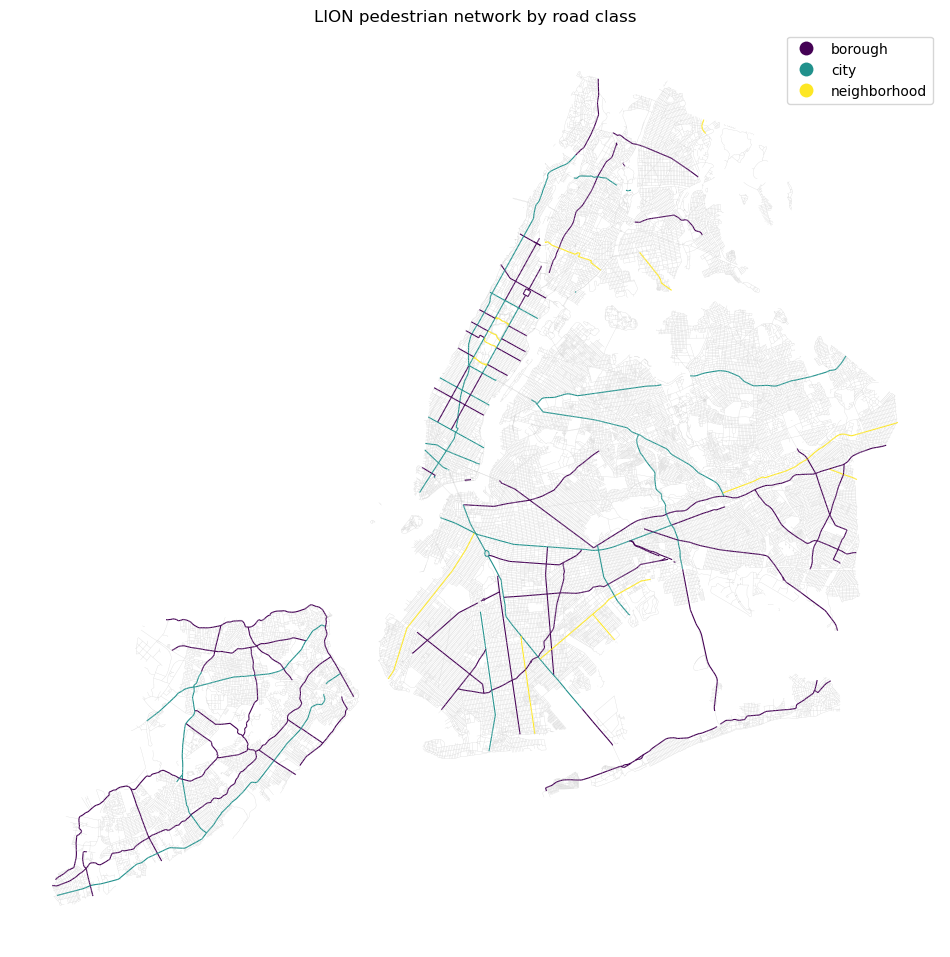

In [26]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(12, 12))

# Local streets first, faint, so the major roads draw on top
lion[lion["road_class"] == "local"].plot(ax=ax, color="lightgray", linewidth=0.2)
lion[lion["road_class"] != "local"].plot(
    ax=ax, column="road_class", linewidth=0.8, legend=True, cmap="viridis"
)

lion = lion.drop(columns=["Carto_Display_Level", "road_class"])

ax.set_axis_off()
ax.set_title("LION pedestrian network by road class")
plt.show()